## Step 1 : Setup


In [1]:
from pathlib import Path
import json
import shutil
from collections import Counter, defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt

coco_root = Path(r"C:\Users\shiif\Downloads\coco2017")
annotations_dir = coco_root / "annotations"

train_annotation_path = annotations_dir / "instances_train2017.json"
val_annotation_path = annotations_dir / "instances_val2017.json"

print("Train annotations path:", train_annotation_path)
print("Val annotations path:  ", val_annotation_path)


Train annotations path: C:\Users\shiif\Downloads\coco2017\annotations\instances_train2017.json
Val annotations path:   C:\Users\shiif\Downloads\coco2017\annotations\instances_val2017.json


## Step 2: Compute COCO Statistics


In [2]:
def load_coco_annotations(json_path):
    with open(json_path, "r") as f:
        return json.load(f)

def compute_class_statistics(coco_data):
    category_id_to_name = {cat["id"]: cat["name"] for cat in coco_data["categories"]}

    instance_counts = Counter()            
    images_per_class = defaultdict(set)    

    for ann in tqdm(coco_data["annotations"], desc="Processing annotations"):
        class_name = category_id_to_name[ann["category_id"]]
        instance_counts[class_name] += 1
        images_per_class[class_name].add(ann["image_id"])

    image_counts = {name: len(ids) for name, ids in images_per_class.items()}
    return instance_counts, image_counts


In [3]:
train_data = load_coco_annotations(train_annotation_path)
val_data = load_coco_annotations(val_annotation_path)

train_instance_counts, train_image_counts = compute_class_statistics(train_data)
val_instance_counts, val_image_counts = compute_class_statistics(val_data)

all_class_names = sorted(cat["name"] for cat in train_data["categories"])

coco_stats_df = pd.DataFrame([
    {
        "Class": name,
        "Train Images": train_image_counts.get(name, 0),
        "Train Instances": train_instance_counts.get(name, 0),
        "Val Images": val_image_counts.get(name, 0),
        "Val Instances": val_instance_counts.get(name, 0),
    }
    for name in all_class_names
]).sort_values(by="Train Instances", ascending=False).reset_index(drop=True)

pd.set_option("display.max_rows", None)

print("COCO class statistics (all classes, sorted by Train Instances):")
coco_stats_df



Processing annotations: 100%|██████████| 36781/36781 [00:00<00:00, 1109119.05it/s]

COCO class statistics (all classes, sorted by Train Instances):


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,64115,262465,2693,11004
1,car,12251,43867,535,1932
2,chair,12774,38491,580,1791
3,book,5332,24715,230,1161
4,bottle,8501,24342,379,1025
5,cup,9189,20650,390,899
6,dining table,11837,15714,501,697
7,bowl,7111,14358,314,626
8,traffic light,4139,12884,191,637
9,handbag,6841,12354,292,540


## Step 3: Removing images with iscrowd=1 

In [4]:
# --- Remove entire images that have any annotation with iscrowd=1 ---

def remove_crowd_images(coco_data):
    # Find every image_id that has at least one crowd annotation
    crowd_image_ids = set(
        ann["image_id"] for ann in coco_data["annotations"] if ann.get("iscrowd", 0) == 1
    )

    original_image_count = len(coco_data["images"])
    original_annotation_count = len(coco_data["annotations"])

    # Keep only images NOT in the crowd set
    filtered_images = [img for img in coco_data["images"] if img["id"] not in crowd_image_ids]
    # Keep only annotations belonging to a surviving image
    filtered_annotations = [ann for ann in coco_data["annotations"] if ann["image_id"] not in crowd_image_ids]

    filtered_data = {
        "images": filtered_images,
        "annotations": filtered_annotations,
        "categories": coco_data["categories"],
    }

    return filtered_data, len(crowd_image_ids), original_image_count, original_annotation_count


train_data_no_crowd, train_removed_count, train_original_images, train_original_annotations = remove_crowd_images(train_data)
val_data_no_crowd, val_removed_count, val_original_images, val_original_annotations = remove_crowd_images(val_data)

print("Train split:")
print(f"  Images before: {train_original_images:,}")
print(f"  Images removed (had iscrowd=1): {train_removed_count:,}")
print(f"  Images left: {len(train_data_no_crowd['images']):,}")
print(f"  Annotations before: {train_original_annotations:,}")
print(f"  Annotations left: {len(train_data_no_crowd['annotations']):,}")

print("\nVal split:")
print(f"  Images before: {val_original_images:,}")
print(f"  Images removed (had iscrowd=1): {val_removed_count:,}")
print(f"  Images left: {len(val_data_no_crowd['images']):,}")
print(f"  Annotations before: {val_original_annotations:,}")
print(f"  Annotations left: {len(val_data_no_crowd['annotations']):,}")

Train split:
  Images before: 118,287
  Images removed (had iscrowd=1): 9,115
  Images left: 109,172
  Annotations before: 860,001
  Annotations left: 654,212

Val split:
  Images before: 5,000
  Images removed (had iscrowd=1): 411
  Images left: 4,589
  Annotations before: 36,781
  Annotations left: 27,436


## Step 4: Recompute class statistics

In [5]:
# --- Recompute per-class statistics after removing iscrowd=1 images ---

train_instance_counts_nc, train_image_counts_nc = compute_class_statistics(train_data_no_crowd)
val_instance_counts_nc, val_image_counts_nc = compute_class_statistics(val_data_no_crowd)

all_class_names_nc = sorted(cat["name"] for cat in train_data_no_crowd["categories"])

coco_stats_df_no_crowd = pd.DataFrame([
    {
        "Class": name,
        "Train Images": train_image_counts_nc.get(name, 0),
        "Train Instances": train_instance_counts_nc.get(name, 0),
        "Val Images": val_image_counts_nc.get(name, 0),
        "Val Instances": val_instance_counts_nc.get(name, 0),
    }
    for name in all_class_names_nc
]).sort_values(by="Train Instances", ascending=False).reset_index(drop=True)

print("COCO class statistics after removing iscrowd=1 images (sorted by Train Instances):")
coco_stats_df_no_crowd

Processing annotations: 100%|██████████| 27436/27436 [00:00<00:00, 745414.96it/s]

COCO class statistics after removing iscrowd=1 images (sorted by Train Instances):


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,56985,181373,2369,7402
1,car,10865,35566,469,1532
2,chair,10909,26488,490,1225
3,bottle,7728,19057,340,786
4,cup,8564,17813,354,753
5,book,4580,15385,191,680
6,dining table,10996,13545,456,571
7,bowl,6652,12852,287,515
8,traffic light,3564,10405,166,536
9,handbag,5488,8610,233,384


## Step 3: Choose Five Classes

In [6]:
# --- Same threshold condition, applied to the cleaned stats table ---
MIN_TRAIN_INSTANCES = 4000
MIN_VAL_INSTANCES = 500

qualifying_df_nc = coco_stats_df_no_crowd[
    (coco_stats_df_no_crowd["Train Instances"] >= MIN_TRAIN_INSTANCES)
    & (coco_stats_df_no_crowd["Val Instances"] >= MIN_VAL_INSTANCES)
].sort_values(by="Train Instances", ascending=False)

selected_classes_no_crowd = qualifying_df_nc["Class"].head(5).tolist()

print("Selected classes (no-crowd dataset):")
for name in selected_classes_no_crowd:
    print(" -", name)

coco_stats_df_no_crowd[coco_stats_df_no_crowd["Class"].isin(selected_classes_no_crowd)].reset_index(drop=True)

Selected classes (no-crowd dataset):
 - person
 - car
 - chair
 - bottle
 - cup


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,56985,181373,2369,7402
1,car,10865,35566,469,1532
2,chair,10909,26488,490,1225
3,bottle,7728,19057,340,786
4,cup,8564,17813,354,753


## Step 4: Create Dataset Directory

In [7]:
# --- New, separate dataset root for the no-crowd version ---
dataset_root_no_crowd = Path("datasets") / "coco_no_crowd"

if dataset_root_no_crowd.exists():
    shutil.rmtree(dataset_root_no_crowd)

for folder in [
    dataset_root_no_crowd / "images" / "train",
    dataset_root_no_crowd / "images" / "val",
    dataset_root_no_crowd / "labels" / "train",
    dataset_root_no_crowd / "labels" / "val",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("No-crowd dataset folder structure created at:", dataset_root_no_crowd.resolve())

No-crowd dataset folder structure created at: C:\Users\shiif\Downloads\yoloduke\datasets\coco_no_crowd


## Step 5: Build Class and Image Lookups

In [8]:
class_name_to_index_no_crowd = {name: idx for idx, name in enumerate(selected_classes_no_crowd)}

category_id_to_name_nc = {cat["id"]: cat["name"] for cat in train_data_no_crowd["categories"]}
category_id_to_new_index_no_crowd = {
    cat_id: class_name_to_index_no_crowd[name]
    for cat_id, name in category_id_to_name_nc.items()
    if name in class_name_to_index_no_crowd
}

def build_image_info(coco_data):
    return {img["id"]: {"file_name": img["file_name"], "width": img["width"], "height": img["height"]}
            for img in coco_data["images"]}

train_image_info_no_crowd = build_image_info(train_data_no_crowd)
val_image_info_no_crowd = build_image_info(val_data_no_crowd)

print("Class index mapping (no-crowd):")
for name, idx in class_name_to_index_no_crowd.items():
    print(f"  {idx}: {name}")

Class index mapping (no-crowd):
  0: person
  1: car
  2: chair
  3: bottle
  4: cup


## Step 6: Filter Annotations

In [ ]:


train_annotations_left = len(train_data_no_crowd["annotations"])
val_annotations_left = len(val_data_no_crowd["annotations"])

print("Train split:")
print(f"  Images before: {train_original_images:,}")
print(f"  Images removed (had iscrowd=1): {train_removed_count:,}")
print(f"  Images left: {len(train_data_no_crowd['images']):,}")
print(f"  Annotations before: {train_original_annotations:,}")
print(f"  Annotations left: {train_annotations_left:,}")

print("\nVal split:")
print(f"  Images before: {val_original_images:,}")
print(f"  Images removed (had iscrowd=1): {val_removed_count:,}")
print(f"  Images left: {len(val_data_no_crowd['images']):,}")
print(f"  Annotations before: {val_original_annotations:,}")
print(f"  Annotations left: {val_annotations_left:,}")

Train split:
  Images before: 118,287
  Images removed (had iscrowd=1): 9,115
  Images left: 109,172
  Annotations before: 860,001
  Annotations left: 654,212

Val split:
  Images before: 5,000
  Images removed (had iscrowd=1): 411
  Images left: 4,589
  Annotations before: 36,781
  Annotations left: 27,436


In [16]:
def filter_annotations_by_image(coco_data, category_id_to_new_index):
    selected_ids = set(category_id_to_new_index.keys())
    annotations_by_image = defaultdict(list)

    for ann in tqdm(coco_data["annotations"], desc="Filtering annotations"):
        if ann["category_id"] in selected_ids:
            annotations_by_image[ann["image_id"]].append(ann)

    return annotations_by_image

train_annotations_by_image_no_crowd = filter_annotations_by_image(train_data_no_crowd, category_id_to_new_index_no_crowd)
val_annotations_by_image_no_crowd = filter_annotations_by_image(val_data_no_crowd, category_id_to_new_index_no_crowd)

print("Training images with a selected class (no-crowd):  ", len(train_annotations_by_image_no_crowd))
print("Training images with a selected class (before):   77100")
print("Validation images with a selected class (no-crowd):", len(val_annotations_by_image_no_crowd))
print("Validation images with a selected class(before): 3283") 

Filtering annotations: 100%|██████████| 27436/27436 [00:00<00:00, 933738.97it/s]

Training images with a selected class (no-crowd):   70214
Training images with a selected class (before):   77100
Validation images with a selected class (no-crowd): 2952
Validation images with a selected class(before): 3283


In [10]:
# --- Convert one COCO bbox [x_min, y_min, w, h] to YOLO [x_center, y_center, w, h] (normalized) ---
def coco_bbox_to_yolo(bbox, image_width, image_height):
    x_min, y_min, box_width, box_height = bbox
    x_center = (x_min + box_width / 2) / image_width
    y_center = (y_min + box_height / 2) / image_height
    return x_center, y_center, box_width / image_width, box_height / image_height


# --- Copy images + write labels for one split (train or val) ---
def build_dataset_split(split_name, source_images_dir, image_info, annotations_by_image, category_id_to_new_index):
    destination_images_dir = dataset_root_no_crowd / "images" / split_name
    destination_labels_dir = dataset_root_no_crowd / "labels" / split_name

    for image_id, annotations in tqdm(annotations_by_image.items(), desc=f"Writing {split_name} set"):
        info = image_info[image_id]
        file_name = info["file_name"]

        # Copy the image
        shutil.copy(source_images_dir / file_name, destination_images_dir / file_name)

        # Build the label lines for this image
        label_lines = []
        for ann in annotations:
            class_index = category_id_to_new_index[ann["category_id"]]
            x_c, y_c, w, h = coco_bbox_to_yolo(ann["bbox"], info["width"], info["height"])
            label_lines.append(f"{class_index} {x_c:.6f} {y_c:.6f} {w:.6f} {h:.6f}")

        # Write the label file (same base name as the image)
        label_path = destination_labels_dir / (Path(file_name).stem + ".txt")
        with open(label_path, "w") as f:
            f.write("\n".join(label_lines))


build_dataset_split( "train", coco_root / "train2017", train_image_info_no_crowd,
                        train_annotations_by_image_no_crowd, category_id_to_new_index_no_crowd)
build_dataset_split( "val", coco_root / "val2017", val_image_info_no_crowd,
                        val_annotations_by_image_no_crowd, category_id_to_new_index_no_crowd)

print("No-crowd dataset created at:", dataset_root_no_crowd.resolve())

Writing val set: 100%|██████████| 2952/2952 [00:13<00:00, 222.93it/s]

No-crowd dataset created at: C:\Users\shiif\Downloads\yoloduke\datasets\coco_no_crowd


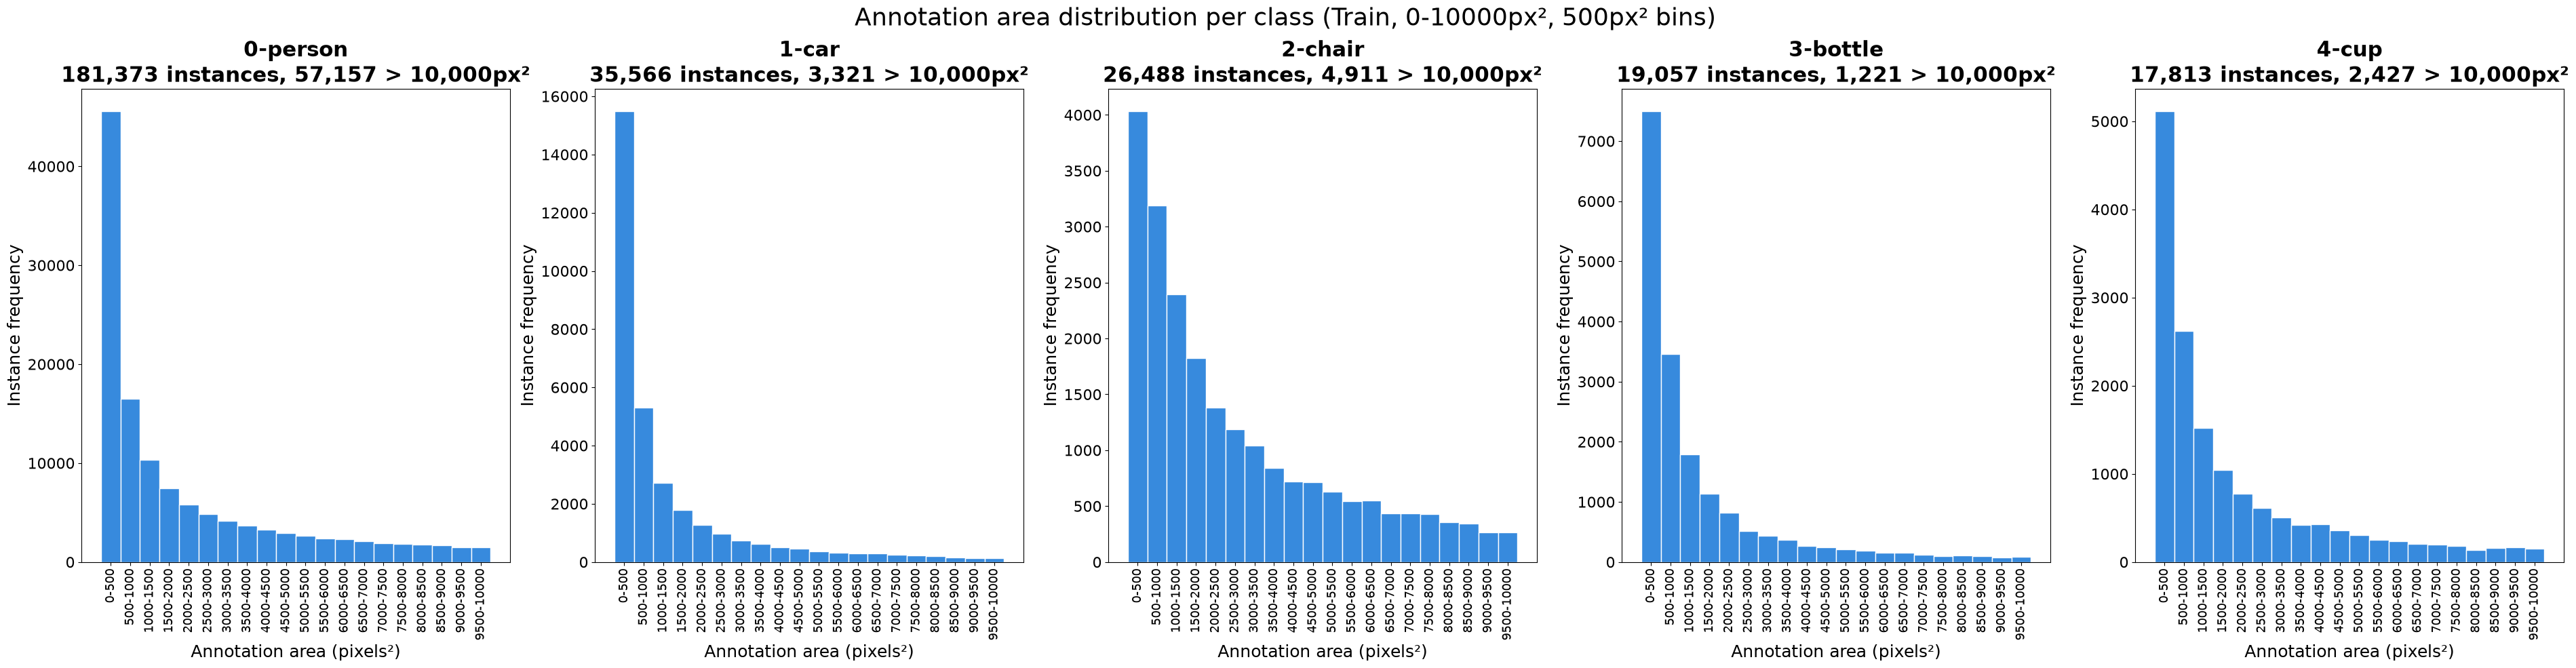

In [11]:
# --- Histogram: annotation area distribution per class (Train, no-crowd), range 0-10000 ---
import numpy as np

index_to_class_name_no_crowd = {idx: name for name, idx in class_name_to_index_no_crowd.items()}

areas_by_class = {name: [] for name in selected_classes_no_crowd}
for image_id, annotations in train_annotations_by_image_no_crowd.items():
    for ann in annotations:
        class_index = category_id_to_new_index_no_crowd[ann["category_id"]]
        class_name = index_to_class_name_no_crowd[class_index]
        area = ann["area"]  
        areas_by_class[class_name].append(area)

X_AXIS_MAX = 10000
BIN_WIDTH = 500
bin_edges = np.arange(0, X_AXIS_MAX + 1, BIN_WIDTH)
bin_range_labels = [f"{int(bin_edges[i])}-{int(bin_edges[i+1])}" for i in range(len(bin_edges) - 1)]
bin_centers = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in range(len(bin_edges) - 1)]

fig, axes = plt.subplots(1, 5, figsize=(38, 10))

for ax, class_name in zip(axes, selected_classes_no_crowd):
    areas = areas_by_class[class_name]
    class_index = class_name_to_index_no_crowd[class_name]
    out_of_range_count = sum(1 for a in areas if a > X_AXIS_MAX)

    ax.hist(areas, bins=bin_edges, range=(0, X_AXIS_MAX), color="#378ADD", edgecolor="white")

    ax.set_title(f"{class_index}-{class_name}\n{len(areas):,} instances, {out_of_range_count:,} > {X_AXIS_MAX:,}px²",
                 fontsize=22, fontweight="bold")
    ax.set_xlabel("Annotation area (pixels²)", fontsize=18)
    ax.set_ylabel("Instance frequency", fontsize=18)
    ax.set_xticks(bin_centers)
    ax.set_xticklabels(bin_range_labels, rotation=90, fontsize=13)
    ax.tick_params(axis="y", labelsize=16)

plt.suptitle("Annotation area distribution per class (Train, 0-10000px², 500px² bins)", fontsize=26)
plt.tight_layout()
plt.show()

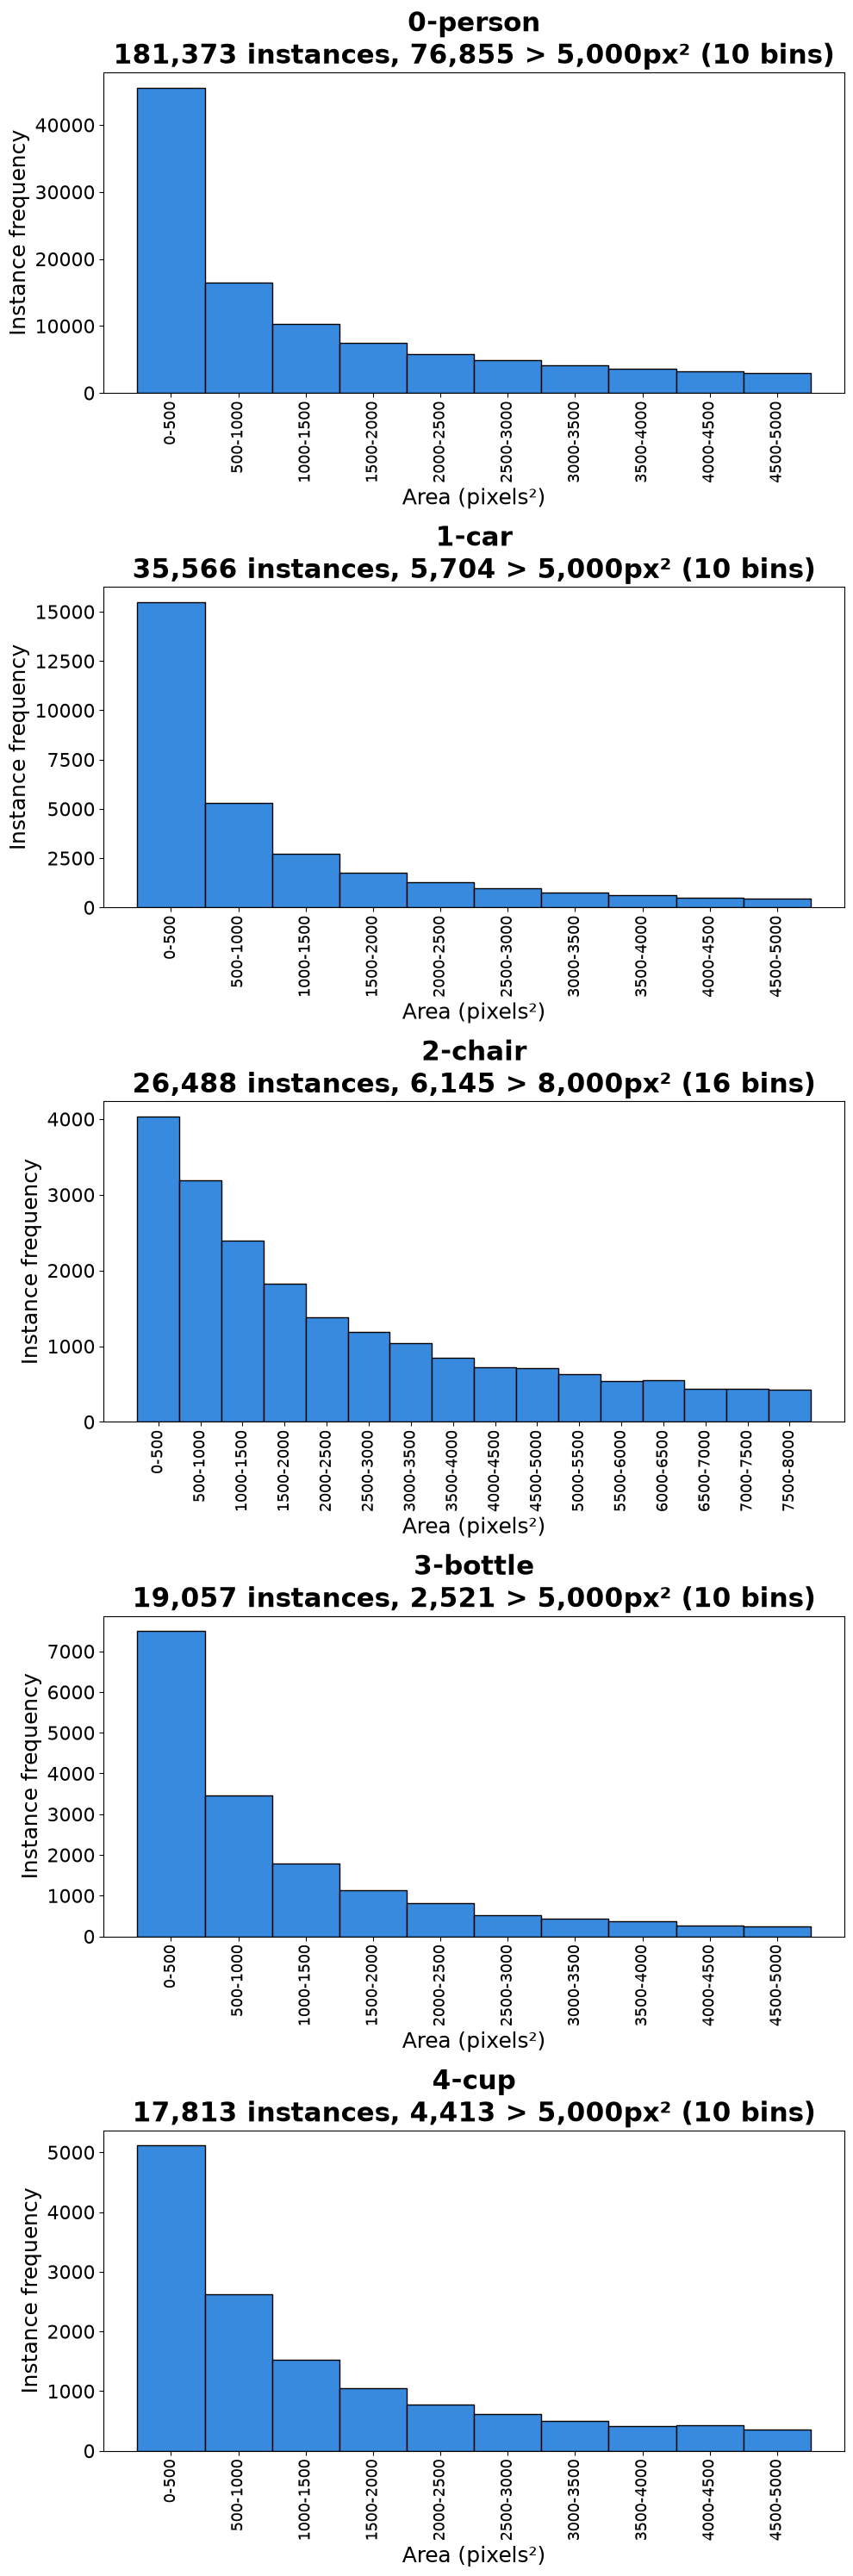

In [12]:
# --- Histogram: annotation area distribution per class (Train, no-crowd), per-class range ---
import numpy as np

index_to_class_name_no_crowd = {idx: name for name, idx in class_name_to_index_no_crowd.items()}

areas_by_class = {name: [] for name in selected_classes_no_crowd}
for image_id, annotations in train_annotations_by_image_no_crowd.items():
    for ann in annotations:
        class_index = category_id_to_new_index_no_crowd[ann["category_id"]]
        class_name = index_to_class_name_no_crowd[class_index]
        area = ann["area"]  
        areas_by_class[class_name].append(area)

BIN_WIDTH = 500
x_axis_max_by_class = {name: 8000 if name == "chair" else 5000 for name in selected_classes_no_crowd}

fig, axes = plt.subplots(5, 1, figsize=(10, 30))

for ax, class_name in zip(axes, selected_classes_no_crowd):
    areas = areas_by_class[class_name]
    class_index = class_name_to_index_no_crowd[class_name]

    x_axis_max = x_axis_max_by_class[class_name]
    num_bins = x_axis_max // BIN_WIDTH
    bin_edges = np.arange(0, x_axis_max + 1, BIN_WIDTH)
    bin_range_labels = [f"{int(bin_edges[i])}-{int(bin_edges[i+1])}" for i in range(len(bin_edges) - 1)]
    bin_centers = [(bin_edges[i] + bin_edges[i+1]) / 2 for i in range(len(bin_edges) - 1)]

    out_of_range_count = sum(1 for a in areas if a > x_axis_max)

    ax.hist(areas, bins=bin_edges, range=(0, x_axis_max), color="#378ADD", edgecolor="black")

    ax.set_title(
        f"{class_index}-{class_name}\n{len(areas):,} instances, {out_of_range_count:,} > {x_axis_max:,}px² ({num_bins} bins)",
        fontsize=22, fontweight="bold"
    )
    ax.set_xlabel("Area (pixels²)", fontsize=18)
    ax.set_ylabel("Instance frequency", fontsize=18)
    ax.set_xticks(bin_centers)
    ax.set_xticklabels(bin_range_labels, rotation=90, fontsize=13)
    ax.tick_params(axis="y", labelsize=16)


plt.tight_layout()
plt.show()